# Copilote User Identification


## Problem-Solving Workflow

The project follows the steps below:

- Understand the problem and the available data
- Load the raw data into memory
- Perform an initial exploratory analysis
- Build relevant features
- Compute basic statistics on the engineered variables
- Develop an automatic classification solution
- Evaluate the solution
- Discuss and interpret the results


## Software User Identification


The first step when working with data in Python is to load it into memory so that it can be inspected more easily. Several approaches are possible, including:

- using the Pandas library and methods that directly load data into DataFrames, such as `read_csv`,
- opening the text file in read mode with `open()` and iterating through the lines using `readlines()`.

The second approach is more robust for the structure of the input file. The delimiter separating the different user actions must first be identified and then used to reconstruct the sequence of actions performed during each session.


In [1]:
import pandas as pd

def read_ds(ds_name: str):
    with open(f'{ds_name}.csv') as f:
        max_actions = max(( len( str(c).split(",")) for c in f.readlines() ))
        f.seek(0)
        _names = ["util", "navigateur"] if "train" in ds_name else ["navigateur"]
        _names.extend(range(max_actions - len(_names)))
        return pd.read_csv(f, names=_names, dtype= str)

In [2]:
features_train = read_ds("train")
features_test = read_ds("test")

features_train.columns = ['util', 'navigateur', *features_train.columns[2:]]
features_test.columns = ['navigateur', *features_test.columns[1:]]
features_train.shape, features_test.shape

((3279, 14470), (324, 7726))

In [3]:
features_train.head()

,util,navigateur,0,1,2,3,4,5,6,7,...,14458,14459,14460,14461,14462,14463,14464,14465,14466,14467
0,nuh,Firefox,CrÃ©ation d'un Ã©cran(infologic.core.accueil.A...,Affichage d'une dialogue,ExÃ©cution d'un bouton,Fermeture d'une dialogue,Affichage d'une dialogue,ExÃ©cution d'un bouton,Fermeture d'une dialogue,CrÃ©ation d'un Ã©cran(infologic.core.gui.contr...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,muz,Google Chrome,CrÃ©ation d'un Ã©cran(infologic.core.gui.contr...,CrÃ©ation d'un Ã©cran(infologic.core.gui.contr...,t5,SÃ©lection dâ€™un onglet(infologic.orga.module...,t10,ExÃ©cution d'un bouton,t15,SÃ©lection dâ€™un onglet,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,zrx,Microsoft Edge,Affichage d'une dialogue(infologic.core.gui.co...,ExÃ©cution d'un bouton,Chainage,Fermeture d'une dialogue,Affichage d'une dialogue(infologic.acti.module...,Clic sur une grille d'historique de recherche,Raccourci,Fermeture d'une dialogue,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,pou,Firefox,CrÃ©ation d'un Ã©cran(infologic.core.gui.contr...,t5,ExÃ©cution d'un bouton(MAINT),Affichage d'une dialogue,Fermeture d'une dialogue,Double-clic,ExÃ©cution d'un bouton,Lancement d'une stat(infologic.core.gui.contro...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ald,Google Chrome,Affichage d'une dialogue(infologic.acti.module...,t5,ExÃ©cution d'un bouton,Fermeture d'une dialogue,t10,EntrÃ©e en saisie dans un formulaire,t10,Affichage d'une dialogue,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Initial Data Analysis


The data contain the user identifier (i.e. the target variable, available only in the training set), the browser selected by the user, and all actions performed during the current session. A special marker of the form `tXX` represents a 5-second time interval.


In [4]:
features_train.loc[:,:20].head()

,util,navigateur,0,1,2,3,4,5,6,7,...,11,12,13,14,15,16,17,18,19,20
0,nuh,Firefox,CrÃ©ation d'un Ã©cran(infologic.core.accueil.A...,Affichage d'une dialogue,ExÃ©cution d'un bouton,Fermeture d'une dialogue,Affichage d'une dialogue,ExÃ©cution d'un bouton,Fermeture d'une dialogue,CrÃ©ation d'un Ã©cran(infologic.core.gui.contr...,...,Fermeture d'une dialogue,Double-clic,ExÃ©cution d'un bouton,Lancement d'une stat(infologic.core.gui.contro...,Affichage d'un toast,Lancement d'une stat(infologic.core.gui.contro...,t10,Affichage d'une dialogue(MAINT),ExÃ©cution d'un bouton,Fermeture d'une dialogue
1,muz,Google Chrome,CrÃ©ation d'un Ã©cran(infologic.core.gui.contr...,CrÃ©ation d'un Ã©cran(infologic.core.gui.contr...,t5,SÃ©lection dâ€™un onglet(infologic.orga.module...,t10,ExÃ©cution d'un bouton,t15,SÃ©lection dâ€™un onglet,...,SÃ©lection dâ€™un onglet(MAJ),t25,SÃ©lection d'un Ã©cran(infologic.orga.modules....,SÃ©lection d'un Ã©cran,ExÃ©cution d'un bouton,Chainage,t30,Saisie dans un champ(MAINT)<DEF_03/24>1,Saisie dans un champ1,Saisie dans un champ1
2,zrx,Microsoft Edge,Affichage d'une dialogue(infologic.core.gui.co...,ExÃ©cution d'un bouton,Chainage,Fermeture d'une dialogue,Affichage d'une dialogue(infologic.acti.module...,Clic sur une grille d'historique de recherche,Raccourci,Fermeture d'une dialogue,...,Raccourci,ExÃ©cution d'un bouton,Affichage d'une dialogue,t10,Clic sur une grille d'historique de recherche,Raccourci,ExÃ©cution d'un bouton,Affichage d'une dialogue,Fermeture d'une dialogue,Clic sur une grille d'historique de recherche
3,pou,Firefox,CrÃ©ation d'un Ã©cran(infologic.core.gui.contr...,t5,ExÃ©cution d'un bouton(MAINT),Affichage d'une dialogue,Fermeture d'une dialogue,Double-clic,ExÃ©cution d'un bouton,Lancement d'une stat(infologic.core.gui.contro...,...,SÃ©lection d'un flag,Filtrage / Tri,t15,Affichage d'une dialogue,Clic sur une grille d'historique de recherche,Affichage d'une dialogue,t20,ExÃ©cution d'un bouton,Fermeture d'une dialogue,CrÃ©ation d'un Ã©cran(infologic.acti.modules.A...
4,ald,Google Chrome,Affichage d'une dialogue(infologic.acti.module...,t5,ExÃ©cution d'un bouton,Fermeture d'une dialogue,t10,EntrÃ©e en saisie dans un formulaire,t10,Affichage d'une dialogue,...,SÃ©lection d'un Ã©cran(infologic.crm.modules.C...,ExÃ©cution d'un bouton,Action de table,Affichage d'un toast,Affichage d'une dialogue,Affichage d'une dialogue,ExÃ©cution d'un bouton,Fermeture d'une dialogue,ExÃ©cution d'un bouton,EntrÃ©e en saisie dans un formulaire


The first inspection of the data shows a very large number of columns (14,470), while most of them contain `NaN` values. This is expected because Pandas expands shorter rows so that every row has the same number of columns, filling missing fields with `NaN`. A small number of users kept sessions open for a very long time, whereas most sessions were short or of moderate duration. These unusually long sessions therefore caused all shorter sessions to be padded with missing values.


navigateur
Firefox           1466
Google Chrome     1339
Microsoft Edge     451
Opera               23
Name: count, dtype: int64

<Axes: xlabel='navigateur'>

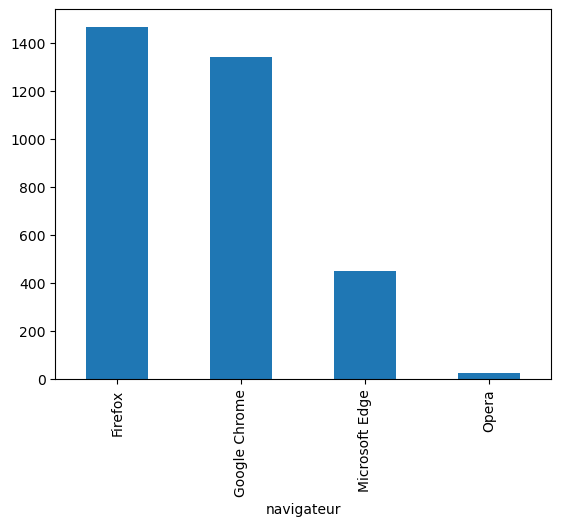

In [5]:
# Explore the different values of the browser :
browser_values = set(features_train["navigateur"])
display(features_train['navigateur'].value_counts())
features_train['navigateur'].value_counts().plot.bar()

Some utility functions that may be useful during the analysis:


In [6]:
import warnings
from IPython.display import display, Markdown
import matplotlib.pyplot as plt
import math as math

# Utility decorators to suppress warnings from the output and print a DataFrame as a Markdown table.
def ignore_warnings(f):
    def _f(*args, **kwargs):
        warnings.filterwarnings('ignore')
        v = f(*args, **kwargs)
        warnings.filterwarnings('default')
        return v
    return _f

# Displays a Pandas DataFrame as a Markdown table in a Jupyter notebook.
def markdown_table(headNtail=False, use_index=True, title=None, precision=2):
    def _get_value(val): return str(round(val, precision) if isinstance(val, float) else val)
    def _format_row(row): 
        row_str = ""
        if use_index: row_str += f"|{str(row.name)}"
        for value in row.values: row_str += f"| {_get_value(value)}"
        return row_str + "|"
    def _get_str(df):
        return "\n".join(df.apply(_format_row, axis=1))
    def _deco(f):
        def _f(*args, **kwargs):
            df = f(*args, **kwargs)
            _str = f"#### {title}\n" if title else ""
            header = ([str(df.index.name)] if use_index else []) + df.columns.astype(str).to_list() 
            _str += f"|{'|'.join(header)}|" + f"\n|{'--|'*len(header)}\n" if header else None
            if headNtail:
                _str += _get_str(df.head())
                _str += "\n|...|...|\n"
                _str += _get_str(df.tail())
            else:
                _str += _get_str(df)
            display(Markdown(_str))
        return _f
    return _deco

# Utility function to create a grid of axes.
def get_grid(n, n_row=1, figsize=(16,4)):
    n_col = math.ceil(n / n_row)
    fig, axs = plt.subplots(nrows=n_row, ncols=n_col, figsize=figsize)

    if n_row == 1 and n_col == 1:
        axs = [[axs]]
    elif n_row == 1:
        axs = [axs]
    elif n_col == 1:
        axs = [[ax] for ax in axs]
    return fig, axs

Now that we have a first overview of the dataset, we can investigate it further and compute descriptive statistics.


In [7]:
@markdown_table(headNtail=True, title="Navigateur par utilisateur")

# Explore browsers :
def browsers_per_player(df) :
    return(pd.crosstab(df["util"], df["navigateur"]))

browsers_per_player(features_train)

#### Navigateur par utilisateur
|util|Firefox|Google Chrome|Microsoft Edge|Opera|
|--|--|--|--|--|
|aho| 0| 10| 0| 0|
|ajo| 13| 0| 0| 0|
|akx| 0| 14| 0| 0|
|ald| 0| 15| 0| 0|
|ats| 12| 0| 0| 0|
|...|...|
|zqs| 0| 0| 16| 0|
|zro| 13| 0| 0| 0|
|zrx| 0| 0| 12| 0|
|zus| 13| 0| 0| 0|
|zyk| 0| 21| 0| 0|

    util  nb_sessions
0    skm           75
1    slq           71
2    cjr           46
3    flj           42
4    hjs           37
..   ...          ...
242  rff            4
243  bez            4
244  crn            4
245  azn            4
246  fyg            4

[247 rows x 2 columns]


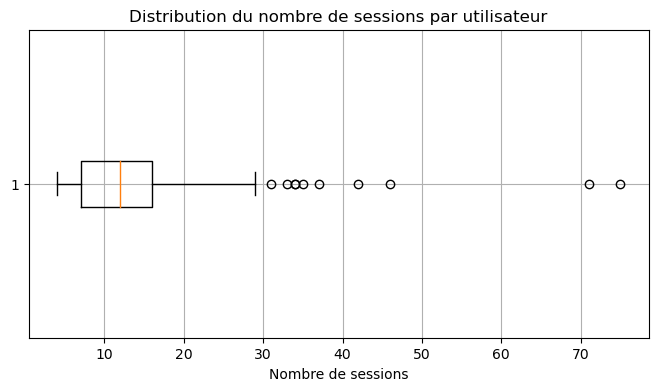

In [8]:
def get_Y_stats(df):
    distribution_util = (
        df["util"]
        .value_counts()
        .reset_index()
        .rename(columns={"count": "nb_sessions"})
    )
    return distribution_util

distribution_util = get_Y_stats(features_train)
print(distribution_util)

plt.figure(figsize=(8,4))
plt.boxplot(distribution_util["nb_sessions"].apply(int), vert=False)
plt.title("Distribution du nombre de sessions par utilisateur")
plt.xlabel("Nombre de sessions")
plt.grid()
plt.show()

## Feature Engineering


### Preliminary Processing

Depending on the selected model, different preprocessing steps may be required. See https://scikit-learn.org/stable/supervised_learning.html for examples of supervised-learning algorithms. Candidate models include:

- Support Vector Machines (SVMs)
- Logistic Regression
- Decision Trees
- Ensemble models (Random Forest, XGBoost, etc.)
- Neural Networks


The first step is to investigate whether the dataset contains outliers and, when necessary, apply an appropriate treatment strategy.


7.0 16.0
   niveau_activité  count       mean  min  max
0    High activity     64  23.484375   16   75
1     Low activity     47   5.085106    4    6
2  Medium activity    136  11.301471    7   15


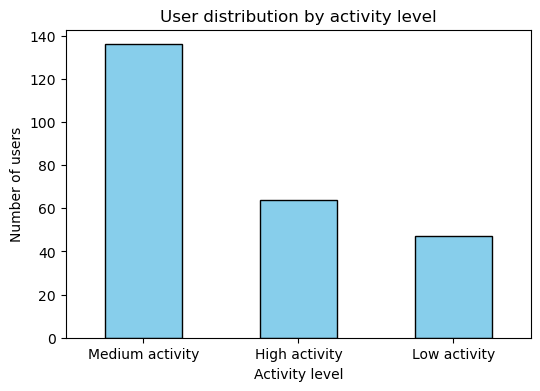

In [11]:
Q1 = distribution_util["nb_sessions"].quantile(0.25)
Q3 = distribution_util["nb_sessions"].quantile(0.75)
print (Q1, Q3)

def categorize_sessions(x):
    if x < Q1:
        return "Low activity"
    elif x < Q3:
        return "Medium activity"
    else:
        return "High activity"

distribution_util["niveau_activité"] = distribution_util["nb_sessions"].apply(categorize_sessions)

stats = distribution_util.groupby("niveau_activité")["nb_sessions"].agg(["count", "mean", "min", "max"]).reset_index()
print(stats)

plt.figure(figsize=(6,4))
distribution_util["niveau_activité"].value_counts().plot(kind="bar", color="skyblue", edgecolor="black")
plt.title("User distribution by activity level")
plt.xlabel("Activity level")
plt.ylabel("Number of users")
plt.xticks(rotation=0)
plt.show()

### Target Variable

The target variable is initially represented as a string. It can be converted into numerical categorical codes using `pd.Categorical`.


In [12]:
features_train["util"] = pd.Categorical(features_train["util"])

`pd.Categorical` does not directly replace the user ID with a number; instead, it provides the `cat.codes` attribute. We can therefore define a small function to convert the target variable from a string representation to its categorical ID.


In [13]:
def to_categories(df, col="util"):
    df[[col]] = df[[col]].apply(lambda x: x.cat.codes)

### Feature Extraction

We now create features from the raw dataset. This requires understanding the log format, parsing the sessions, and determining how the information should be aggregated.


We first create a new DataFrame that will contain the features used by the classification models. The first variables added are the user identifier and the browser, which can be extracted directly from the first columns of the original dataset.


In [14]:
features_train_model = features_train[["util", "navigateur"]]

The first engineered feature is the total duration of the user's session.


In [15]:
import re as re

def temps_total_session(session) : 
    for action in session : 
        if isinstance(action, str) and action.startswith("t") : 
            temps = action 
    return int(temps[1:]) 

features_train_model["temps total"] = features_train.iloc[:, 2:].apply(temps_total_session, axis=1)

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_17664\1292257044.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features_train_model["temps total"] = features_train.iloc[:, 2:].apply(temps_total_session, axis=1)


In [16]:
features_train_model.head()

,util,navigateur,temps total
0,nuh,Firefox,2905
1,muz,Google Chrome,230
2,zrx,Microsoft Edge,750
3,pou,Firefox,1445
4,ald,Google Chrome,275


We now continue the feature-engineering process by examining all distinct actions appearing in the interaction logs. The objective is to understand their structure, parse them correctly, and determine meaningful aggregation strategies. As the total number of all the actions is high, we display only the 10 first actions in the list :


In [18]:
# Unique activities : 
features_train.iloc[:,2:].stack().unique()
uniques = list(set([un for un in features_train.iloc[:,2:].stack().unique() if not un.startswith("t")]))
len(uniques), uniques[:10]

(7087,
 ['Chainage$OPECO$',
  'Filtrage / Tri$SV$',
  'Retour sur un Ã©cran(DEV)<DEF_07/23>$GMAO$',
  'Raccourci<GP_SuiviDevs>',
  "Fermeture d'un panel(infologic.core.gui.controllers.BlankController)<EV_BK>",
  "Fermeture d'une dialogue$MNG$1",
  "SÃ©lection d'un Ã©cran$SV$",
  "CrÃ©ation d'un Ã©cran<ADM_7299>",
  "Affichage d'une dialogue(infologic.acti.modules.AT_ACTIVITES.compterendu.CompteRenduForm)<RetroSprint>",
  'Raccourci(MAINT)$ST$'])

The raw action logs contain a large number of highly specific interaction events. The filtering step consists of identifying the relevant action patterns, removing unnecessary or overly specific information, and grouping similar events into more general action categories. This makes the data easier to analyze, reduces dimensionality, and helps create meaningful behavioral features for the classification model.

In [19]:
def filter_action(value: str):
    if isinstance(value, str) :
        for delim in [ "(", "<", "$", "1"]:
            if delim in value and (low_ind := value.index(delim)):
                value = value[:low_ind]
    return value

# filtration des actions:
filtered_uniques = list(set([filter_action(un) for un in uniques]))
len(filtered_uniques), filtered_uniques[:10]

(35,
 ["Clic sur une grille d'historique de recherche",
  'Chainage',
  "Affichage d'une dialogue",
  'Raccourci',
  "Lancement d'une action infocentre",
  'Double-clic',
  "Affichage d'un toast",
  "DÃ©marrage serveur d'application Tomcat",
  "Raccourci dans l'Ã©dition de table",
  "Fermeture d'une dialogue"])

The extracted actions are added as features to the new DataFrame in order to characterize user behavior. Another feature is the total number of operations performed during each session.


In [20]:
import numpy as np

# Clean the columns of the actions and delete 'txxxx'
df_filtered = features_train.copy()
df_filtered.iloc[:, 2:] = features_train.iloc[:, 2:].applymap(filter_action)
df_filtered = df_filtered.replace(to_replace=r"^t\d*$", value=np.nan, regex=True)
df_filtered.head()

,util,navigateur,0,1,2,3,4,5,6,7,...,14458,14459,14460,14461,14462,14463,14464,14465,14466,14467
0,nuh,Firefox,CrÃ©ation d'un Ã©cran,Affichage d'une dialogue,ExÃ©cution d'un bouton,Fermeture d'une dialogue,Affichage d'une dialogue,ExÃ©cution d'un bouton,Fermeture d'une dialogue,CrÃ©ation d'un Ã©cran,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,muz,Google Chrome,CrÃ©ation d'un Ã©cran,CrÃ©ation d'un Ã©cran,NaN,SÃ©lection dâ€™un onglet,NaN,ExÃ©cution d'un bouton,NaN,SÃ©lection dâ€™un onglet,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,zrx,Microsoft Edge,Affichage d'une dialogue,ExÃ©cution d'un bouton,Chainage,Fermeture d'une dialogue,Affichage d'une dialogue,Clic sur une grille d'historique de recherche,Raccourci,Fermeture d'une dialogue,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,pou,Firefox,CrÃ©ation d'un Ã©cran,NaN,ExÃ©cution d'un bouton,Affichage d'une dialogue,Fermeture d'une dialogue,Double-clic,ExÃ©cution d'un bouton,Lancement d'une stat,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ald,Google Chrome,Affichage d'une dialogue,NaN,ExÃ©cution d'un bouton,Fermeture d'une dialogue,NaN,EntrÃ©e en saisie dans un formulaire,NaN,Affichage d'une dialogue,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [21]:
# The DataFrame of features (counting the actions)
def build_features(df, filtered_uniques):
    features_list = []
    for idx, row in df.iterrows():
        counts = {action: 0 for action in filtered_uniques}
        for action in row:
            if action in counts:
                counts[action] += 1
        features_list.append(counts)
    features_actions = pd.DataFrame(features_list)
    return features_actions.fillna(0)

features_actions = build_features(df_filtered, filtered_uniques)

# Add the base columns (util, navigateur, etc.)
features_train_model = pd.concat([features_train_model.reset_index(drop=True),
                              features_actions.reset_index(drop=True)], axis=1)

# Total number of actions
features_train_model['num_ops'] = features_train_model[filtered_uniques].sum(axis=1)


features_train_model.head()

,util,navigateur,temps total,Clic sur une grille d'historique de recherche,Chainage,Affichage d'une dialogue,Raccourci,Lancement d'une action infocentre,Double-clic,Affichage d'un toast,...,SÃ©lection d'un Ã©lÃ©ment,Affichage d'une erreur,Lancement d'une action gÃ©nÃ©rique,Clic sur une checkbox,Lancement d'un tableau de bord,Filtrage / Tri,Saisie dans un champ,Dissimulation d'une arborescence,CrÃ©ation d'un Ã©cran,num_ops
0,nuh,Firefox,2905,1,8,350,0,0,87,311,...,0,6,124,0,0,161,198,0,72,2514
1,muz,Google Chrome,230,0,3,2,1,0,0,1,...,0,0,5,0,0,0,34,0,3,90
2,zrx,Microsoft Edge,750,72,32,35,39,0,22,7,...,10,0,35,0,0,1,46,0,36,608
3,pou,Firefox,1445,121,23,42,0,0,2,2,...,0,1,26,0,0,5,84,0,22,886
4,ald,Google Chrome,275,10,4,10,0,0,2,1,...,0,0,7,0,0,0,14,0,10,173


More advanced extraction functions can then be used to identify the most frequently used screen, screen configuration, and record category during a session. Regular expressions (`regex`) are used to extract these elements from the raw logs. Additional information can also be extracted whenever it appears relevant to the prediction task.


In [25]:
features_train_model.head()

,util,navigateur,temps total,Clic sur une grille d'historique de recherche,Chainage,Affichage d'une dialogue,Raccourci,Lancement d'une action infocentre,Double-clic,Affichage d'un toast,...,SÃ©lection d'un Ã©lÃ©ment,Affichage d'une erreur,Lancement d'une action gÃ©nÃ©rique,Clic sur une checkbox,Lancement d'un tableau de bord,Filtrage / Tri,Saisie dans un champ,Dissimulation d'une arborescence,CrÃ©ation d'un Ã©cran,num_ops
0,nuh,Firefox,2905,1,8,350,0,0,87,311,...,0,6,124,0,0,161,198,0,72,2514
1,muz,Google Chrome,230,0,3,2,1,0,0,1,...,0,0,5,0,0,0,34,0,3,90
2,zrx,Microsoft Edge,750,72,32,35,39,0,22,7,...,10,0,35,0,0,1,46,0,36,608
3,pou,Firefox,1445,121,23,42,0,0,2,2,...,0,1,26,0,0,5,84,0,22,886
4,ald,Google Chrome,275,10,4,10,0,0,2,1,...,0,0,7,0,0,0,14,0,10,173


In [26]:
def first_operation(row):
    return filter_action(row.iloc[0])

def last_operation(row):
    non_na = row.dropna()
    return filter_action(non_na.iloc[-1]) if not non_na.empty else np.nan

features_train_model['first_op'] = features_train.iloc[:, 2:].apply(first_operation, axis=1)
features_train_model['last_op'] = features_train.iloc[:, 2:].apply(last_operation, axis=1)

In [27]:
features_train_model.head()

,util,navigateur,temps total,Clic sur une grille d'historique de recherche,Chainage,Affichage d'une dialogue,Raccourci,Lancement d'une action infocentre,Double-clic,Affichage d'un toast,...,Lancement d'une action gÃ©nÃ©rique,Clic sur une checkbox,Lancement d'un tableau de bord,Filtrage / Tri,Saisie dans un champ,Dissimulation d'une arborescence,CrÃ©ation d'un Ã©cran,num_ops,first_op,last_op
0,nuh,Firefox,2905,1,8,350,0,0,87,311,...,124,0,0,161,198,0,72,2514,CrÃ©ation d'un Ã©cran,Fermeture de session
1,muz,Google Chrome,230,0,3,2,1,0,0,1,...,5,0,0,0,34,0,3,90,CrÃ©ation d'un Ã©cran,Fermeture d'une dialogue
2,zrx,Microsoft Edge,750,72,32,35,39,0,22,7,...,35,0,0,1,46,0,36,608,Affichage d'une dialogue,Lancement d'une action gÃ©nÃ©rique
3,pou,Firefox,1445,121,23,42,0,0,2,2,...,26,0,0,5,84,0,22,886,CrÃ©ation d'un Ã©cran,Fermeture de session
4,ald,Google Chrome,275,10,4,10,0,0,2,1,...,7,0,0,0,14,0,10,173,Affichage d'une dialogue,Fermeture de session


We then define sequential features to capture the user's interaction logic. The first step is to extract the actions performed during each session while preserving their original order.


In [28]:
action_cols = df_filtered.columns[2:]

# function that creates the sequence :
def get_action_sequence(row):
    return [str(act) for act in row[action_cols] if pd.notna(act)]

# A new column for the sequence
df_filtered['action_sequence'] = df_filtered.apply(get_action_sequence, axis=1)

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_17664\2258952622.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_filtered['action_sequence'] = df_filtered.apply(get_action_sequence, axis=1)


In [30]:
df_filtered['action_sequence'][0][:5]

["CrÃ©ation d'un Ã©cran",
 "Affichage d'une dialogue",
 "ExÃ©cution d'un bouton",
 "Fermeture d'une dialogue",
 "Affichage d'une dialogue"]

Another feature family captures the sequential organization of operations.


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from itertools import pairwise
from sklearn.feature_extraction.text import CountVectorizer

# TF-IDF on the sequences of actions
df_filtered['action_sequence_str'] = df_filtered['action_sequence'].apply(lambda x: " | ".join(x))
tfidf = TfidfVectorizer(tokenizer=lambda s: s.split(" | "), lowercase=False)
X_tfidf = tfidf.fit_transform(df_filtered['action_sequence_str'])
df_tfidf = pd.DataFrame(X_tfidf.toarray(), columns=[f"tfidf_{w}" 
                                    for w in tfidf.get_feature_names_out()])

# Bigrammes (transitions between actions)
def extract_bigrams(actions):
    return [" → ".join(pair) for pair in pairwise(actions)] if len(actions) > 1 else []

df_filtered['action_bigrams'] = df_filtered['action_sequence'].apply(extract_bigrams)
df_filtered['action_bigrams_str'] = df_filtered['action_bigrams'].apply(lambda x: " | ".join(x))

bigram_vectorizer = TfidfVectorizer(tokenizer=lambda s: s.split(" | "), lowercase=False)
X_bigram = bigram_vectorizer.fit_transform(df_filtered['action_bigrams_str'])
df_bigram = pd.DataFrame(X_bigram.toarray(), columns=[f"trans_{w}" 
                                    for w in bigram_vectorizer.get_feature_names_out()])


# add to features_train_model
features_train_model = pd.concat([features_train_model,
    df_bigram.reset_index(drop=True)
], axis=1)

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_17664\3133946030.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_filtered['action_sequence_str'] = df_filtered['action_sequence'].apply(lambda x: " | ".join(x))
c:\Users\LENOVO\anaconda3\Lib\site-packages\sklearn\feature_extraction\text.py:525: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_17664\3133946030.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_filtered['a

In [33]:
print(features_train_model.columns[-10:])

Index(['trans_SÃ©lection dâ€™un onglet → Lancement d'une action infocentre',
       'trans_SÃ©lection dâ€™un onglet → Lancement d'une stat',
       'trans_SÃ©lection dâ€™un onglet → Ouverture d'un panel',
       'trans_SÃ©lection dâ€™un onglet → Raccourci',
       'trans_SÃ©lection dâ€™un onglet → Retour sur un Ã©cran',
       'trans_SÃ©lection dâ€™un onglet → Saisie dans un champ',
       'trans_SÃ©lection dâ€™un onglet → SÃ©lection d'un flag',
       'trans_SÃ©lection dâ€™un onglet → SÃ©lection d'un Ã©cran',
       'trans_SÃ©lection dâ€™un onglet → SÃ©lection d'un Ã©lÃ©ment',
       'trans_SÃ©lection dâ€™un onglet → SÃ©lection dâ€™un onglet'],
      dtype='object')


### Processing Categorical Variables

The browser column can take only four values. There are two main ways to convert it into a numerical representation:

- encode it as a categorical variable, as done for the target variable,
- use One-Hot Encoding (OHE), with one binary variable per browser. Pandas provides `get_dummies()` for this purpose.

The most appropriate representation depends on the selected model.

In this analysis, categorical encoding is used for string-valued features. This keeps the number of variables limited and makes correlation analysis easier to visualize.


In [34]:
features_train_model["util"] = pd.Categorical(features_train_model["util"])
util_categories = features_train_model["util"].cat.categories

def to_categories(df, col):
    df[[col]] = df[[col]].apply(lambda x: x.cat.codes)

to_categories(features_train_model, col = 'util')

print(util_categories)

Index(['aho', 'ajo', 'akx', 'ald', 'ats', 'avt', 'azn', 'azo', 'azx', 'bez',
       ...
       'zbn', 'zct', 'zht', 'zll', 'zok', 'zqs', 'zro', 'zrx', 'zus', 'zyk'],
      dtype='object', length=247)


In [35]:
from sklearn.preprocessing import LabelEncoder

cols_to_encode = ["navigateur", "first_op", "last_op"]

encoders = {}
for col in cols_to_encode:
    le = LabelEncoder()
    features_train_model[col] = le.fit_transform(features_train_model[col].astype(str))
    encoders[col] = le 

In [36]:
features_train_model.head()

,util,navigateur,temps total,Clic sur une grille d'historique de recherche,Chainage,Affichage d'une dialogue,Raccourci,Lancement d'une action infocentre,Double-clic,Affichage d'un toast,...,trans_SÃ©lection dâ€™un onglet → Lancement d'une action infocentre,trans_SÃ©lection dâ€™un onglet → Lancement d'une stat,trans_SÃ©lection dâ€™un onglet → Ouverture d'un panel,trans_SÃ©lection dâ€™un onglet → Raccourci,trans_SÃ©lection dâ€™un onglet → Retour sur un Ã©cran,trans_SÃ©lection dâ€™un onglet → Saisie dans un champ,trans_SÃ©lection dâ€™un onglet → SÃ©lection d'un flag,trans_SÃ©lection dâ€™un onglet → SÃ©lection d'un Ã©cran,trans_SÃ©lection dâ€™un onglet → SÃ©lection d'un Ã©lÃ©ment,trans_SÃ©lection dâ€™un onglet → SÃ©lection dâ€™un onglet
0,130,0,2905,1,8,350,0,0,87,311,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.003212
1,118,1,230,0,3,2,1,0,0,1,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.054657,0.0,0.000000
2,244,2,750,72,32,35,39,0,22,7,...,0.0,0.0,0.0,0.015082,0.0,0.0,0.0,0.019508,0.0,0.039441
3,146,0,1445,121,23,42,0,0,2,2,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.000000
4,3,1,275,10,4,10,0,0,2,1,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.000000


## Descriptive Statistics on Engineered Features


### Feature Inspection

We inspect the engineered features and visualize their distributions in order to interpret their behavior. Matplotlib is used for the graphical analysis.


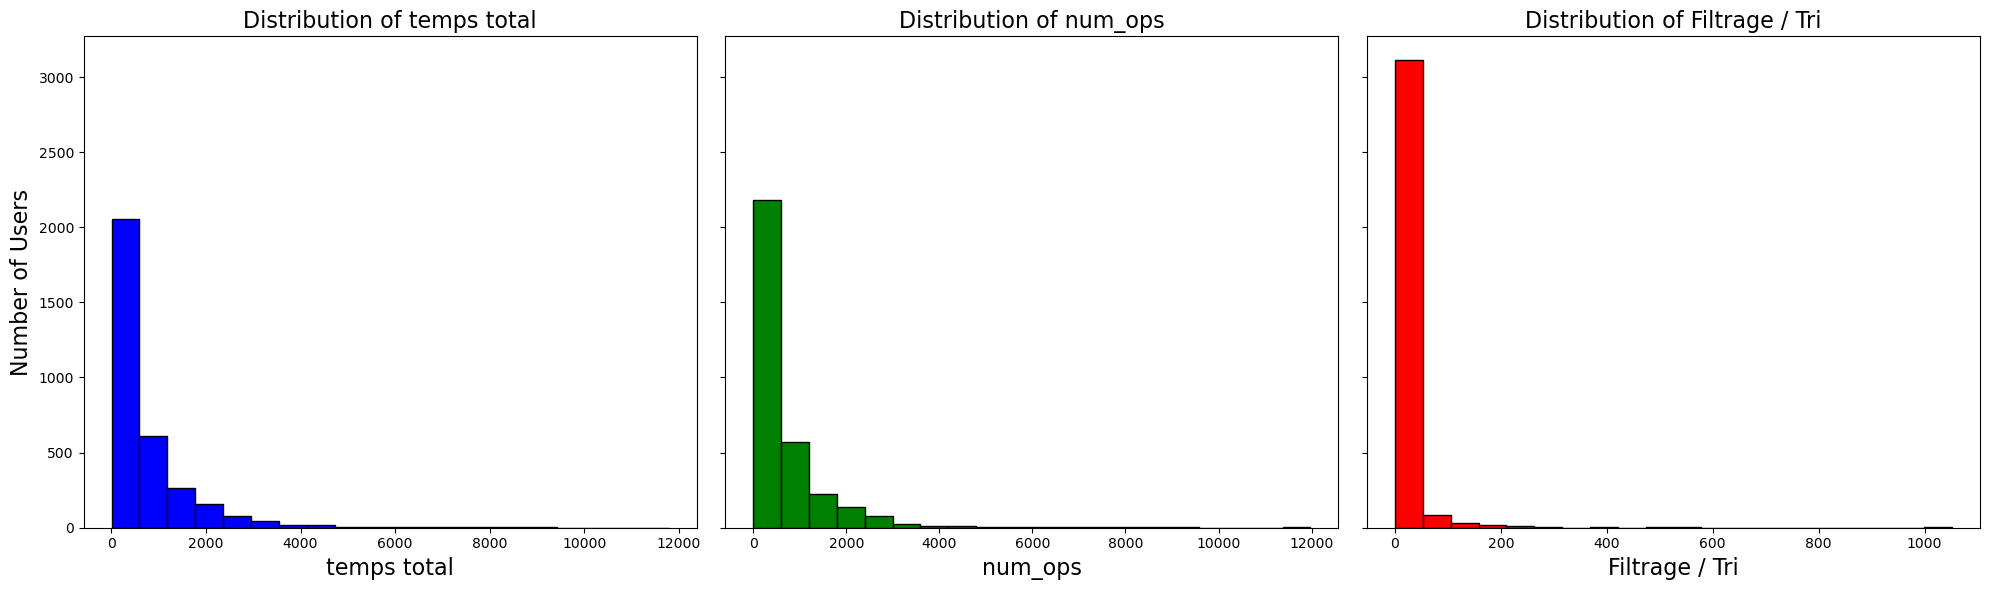

In [37]:
fig, (ax1, ax2, ax3) = plt.subplots(ncols=3, sharey=True, figsize=(20,6))

feature1 = "temps total"
feature2 = "num_ops"
feature3 = "Filtrage / Tri"

# Feature 1
ax1.hist(features_train_model[feature1], bins=20, color='blue', edgecolor='black')
ax1.set_title(f'Distribution of {feature1}', fontsize=16)
ax1.set_xlabel(feature1, fontsize=16)
ax1.set_ylabel('Number of Users', fontsize=16)

# Feature 2
ax2.hist(features_train_model[feature2], bins=20, color='green', edgecolor='black')
ax2.set_title(f'Distribution of {feature2}', fontsize=16)
ax2.set_xlabel(feature2, fontsize=16)

# Feature 3
ax3.hist(features_train_model[feature3], bins=20, color='red', edgecolor='black')
ax3.set_title(f'Distribution of {feature3}', fontsize=16)
ax3.set_xlabel(feature3, fontsize=16)

plt.tight_layout()
plt.show()

### Inspecting Feature Correlation for Selected Classes

Because the problem contains a large number of possible classes, it can be difficult to inspect all of them simultaneously. We therefore begin by visualizing correlations for a limited number of selected target classes.


In [41]:
import seaborn as sns

# Function to plot the distribution of a feature for selected categories
def plot_categories(categories, type_="box", feature="actions_means"):
    fig, axs = get_grid(len(categories), n_row=1, figsize=(16, 4))
    axs = axs[0]

    for i, cat in enumerate(categories):
        data_cat = features_train_model[features_train_model["util"]==cat]
        if type_ == "box":
            sns.boxplot(y=data_cat[feature], ax=axs[i], color='skyblue')
        elif type_ == "violin":
            sns.violinplot(y=data_cat[feature], ax=axs[i], color='lightgreen')
        axs[i].set_title(f"Catégorie {cat}")
        axs[i].set_ylabel(feature)
        axs[i].set_xlabel("")
    
    plt.suptitle(f"Distribution of '{feature}' for selected categories", fontsize=16)
    plt.tight_layout()
    plt.show()

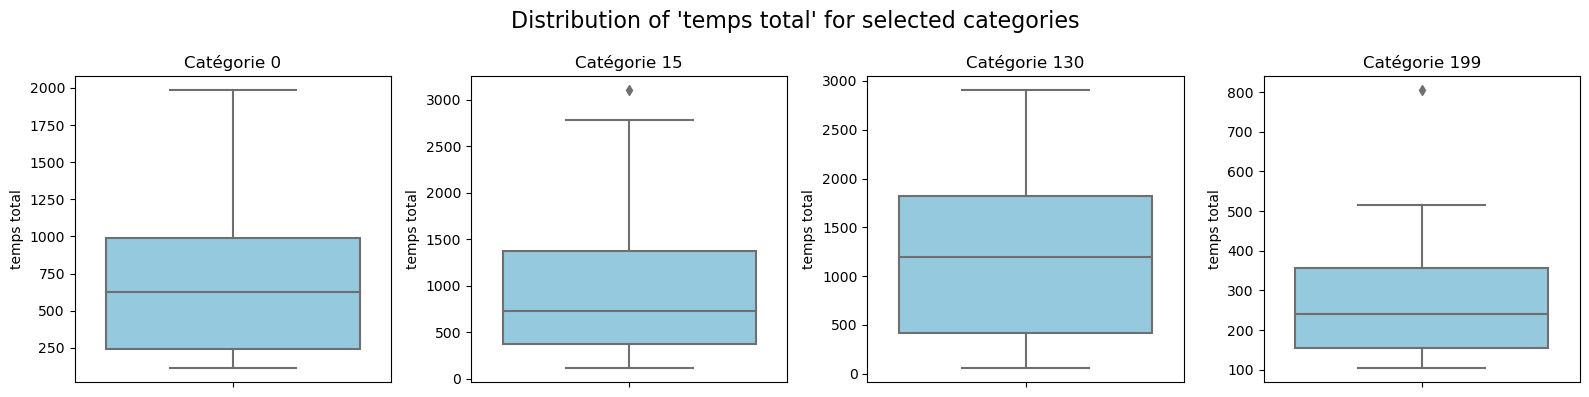

In [42]:
categories = [0, 15, 130, 199]
plot_categories(categories, type_="box", feature="temps total")

Boxplots are particularly useful for estimating the distribution of a feature within a class. Other visualizations, such as violin plots, may also be used.


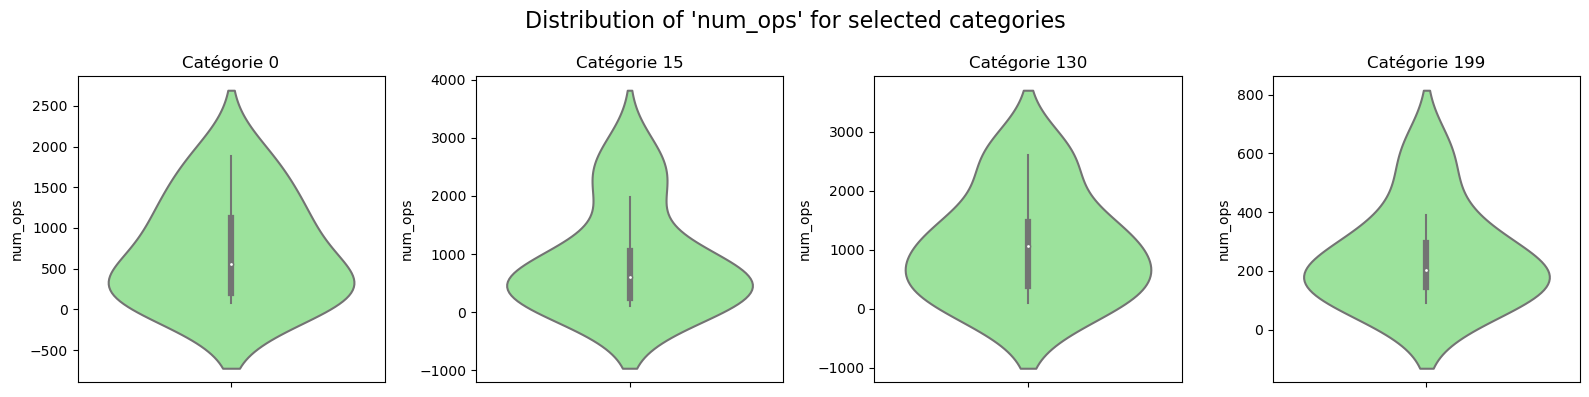

In [43]:
categories = [0, 15, 130, 199]
plot_categories(categories, type_="violin", feature="num_ops")

Evaluation of correlations between features:


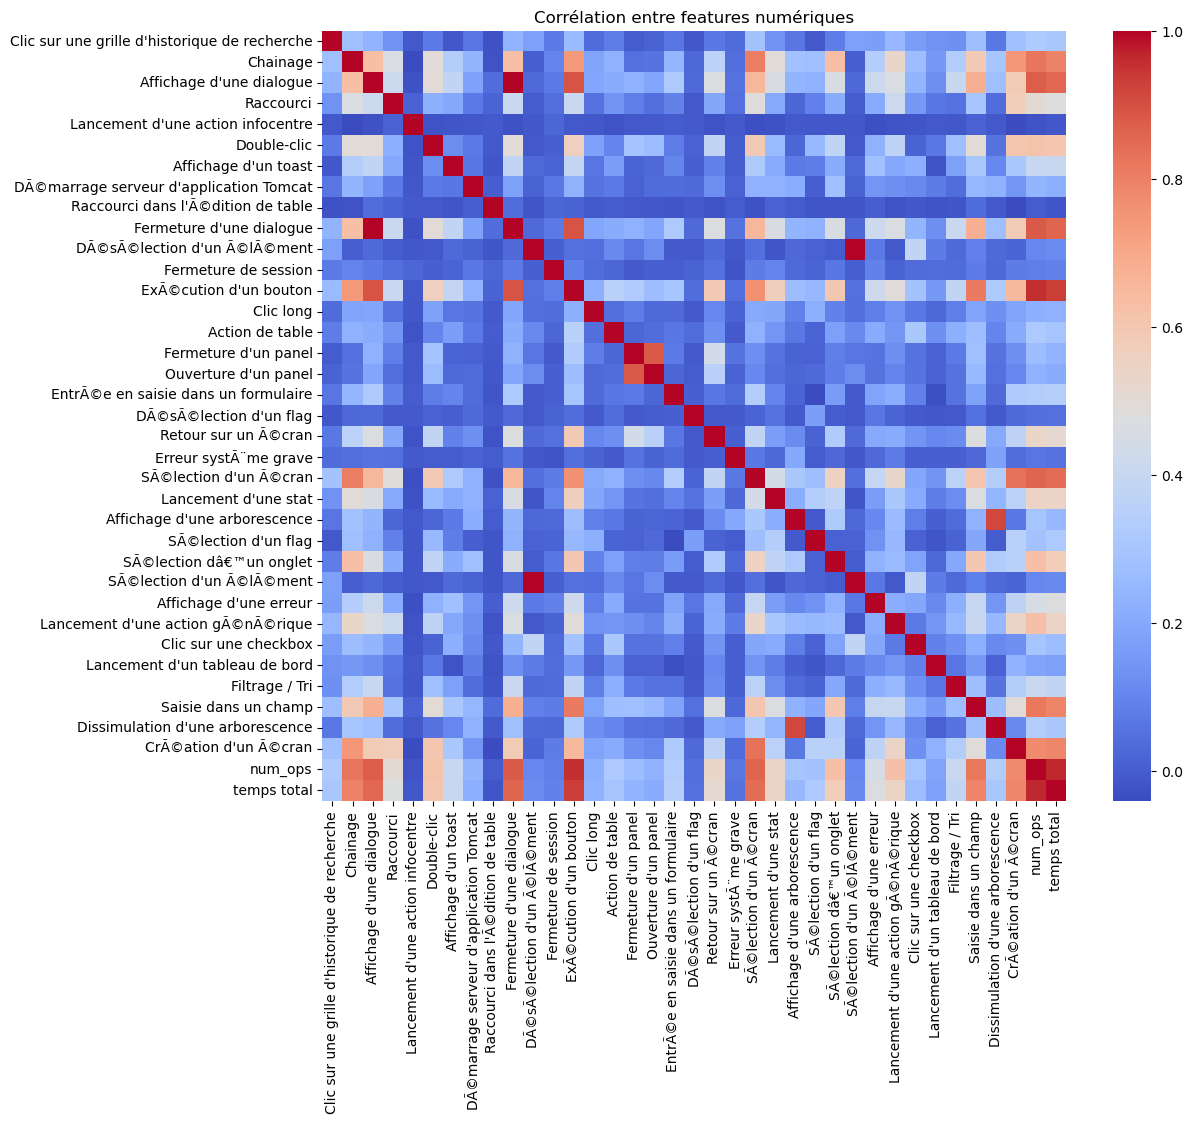

In [44]:
# Selection of numerical columns
numeric_features = features_train_model[filtered_uniques + ['num_ops', 'temps total']]

# Computation of the correlation matrix
corr_matrix = numeric_features.corr(method='pearson')

# Visualization using a heatmap
plt.figure(figsize=(12,10))
sns.heatmap(corr_matrix, annot=False, fmt=".2f", cmap='coolwarm')
plt.title("Corrélation entre features numériques")
plt.show()

The correlation matrix reveals several features that are strongly correlated with other variables and can therefore be considered for removal:

- Item deselection
- Dialog closing
- Number of operations per session


In [45]:
features_train_model= features_train_model.drop(columns=["DÃ©sÃ©lection d'un Ã©lÃ©ment",
"Fermeture d'une dialogue", 'num_ops'])

In [46]:
features_train_model.head()

,util,navigateur,temps total,Clic sur une grille d'historique de recherche,Chainage,Affichage d'une dialogue,Raccourci,Lancement d'une action infocentre,Double-clic,Affichage d'un toast,...,trans_SÃ©lection dâ€™un onglet → Lancement d'une action infocentre,trans_SÃ©lection dâ€™un onglet → Lancement d'une stat,trans_SÃ©lection dâ€™un onglet → Ouverture d'un panel,trans_SÃ©lection dâ€™un onglet → Raccourci,trans_SÃ©lection dâ€™un onglet → Retour sur un Ã©cran,trans_SÃ©lection dâ€™un onglet → Saisie dans un champ,trans_SÃ©lection dâ€™un onglet → SÃ©lection d'un flag,trans_SÃ©lection dâ€™un onglet → SÃ©lection d'un Ã©cran,trans_SÃ©lection dâ€™un onglet → SÃ©lection d'un Ã©lÃ©ment,trans_SÃ©lection dâ€™un onglet → SÃ©lection dâ€™un onglet
0,130,0,2905,1,8,350,0,0,87,311,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.003212
1,118,1,230,0,3,2,1,0,0,1,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.054657,0.0,0.000000
2,244,2,750,72,32,35,39,0,22,7,...,0.0,0.0,0.0,0.015082,0.0,0.0,0.0,0.019508,0.0,0.039441
3,146,0,1445,121,23,42,0,0,2,2,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.000000
4,3,1,275,10,4,10,0,0,2,1,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.000000


## Development of an Automatic Classification Solution


After exploring the data and obtaining a better understanding of the task, we can develop a supervised classification solution.

The dataset is first split into two subsets: a **training set** and a **validation set**. The validation set is used to compare models and select the most appropriate approach. Depending on the algorithms and their computational cost, K-fold cross-validation can also be used.


In [47]:
from sklearn.model_selection import train_test_split

X = features_train_model.drop(columns=['util', 'navigateur'], errors='ignore')
y = features_train_model["util"]

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

Several standard machine-learning algorithms are then evaluated while varying their hyperparameters:

- Logistic Regression
- Support Vector Machines (SVMs) with different kernels
- Decision Trees
- Tree ensembles such as Random Forest and XGBoost
- Artificial Neural Networks (MLP), with different numbers of layers and neurons

Regularization strategies can also be tested when appropriate.

The implementations rely mainly on the `scikit-learn` library.


## Model Evaluation

The models developed in the previous section are used to make predictions on observations that were not seen during training. A validation set is used to estimate their generalization performance.

The next step is to select evaluation metrics that are appropriate for the task. At minimum, classification **accuracy** and the **F1-score** are considered, while additional metrics may also be used when relevant.


Feature scaling is performed using `StandardScaler` where appropriate.


First model evaluated: `RandomForestClassifier`


In [49]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import load_iris
from sklearn.metrics import f1_score


rf_clf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    random_state=42,
 n_jobs=-1
)
rf_clf.fit(X_train, y_train)

y_pred = rf_clf.predict(X_val)
f1 = f1_score(y_val, y_pred, average='macro')

print(f"\nF1-score macro : {f1:.4f}")


F1-score macro : 0.7402


In [50]:
rf_clf = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    min_samples_split=2,
    random_state=42,
 n_jobs=-1
)
rf_clf.fit(X_train, y_train)

y_pred = rf_clf.predict(X_val)
f1 = f1_score(y_val, y_pred, average='macro')

print(f"\nF1-score macro : {f1:.4f}")


F1-score macro : 0.7382


Cross-validation:


In [ ]:
from sklearn.model_selection import cross_val_score, KFold

# --- Define the model ---
rf = RandomForestClassifier(n_estimators=100, random_state=42)

# --- Define K-folds ---
k = 3  # nombre de folds
kf = KFold(n_splits=k, shuffle=True, random_state=42)

# --- Cross validation ---
scores = cross_val_score(rf, X, y, cv=kf, scoring='accuracy')

# --- Results ---
print(f"Scores sur chaque fold : {scores}")
print(f"Précision moyenne : {np.mean(scores):.4f}")

Scores sur chaque fold : [0.76303751 0.75937786 0.75663312]
Précision moyenne : 0.7597


Second model evaluated: Linear SVC


In [52]:
from sklearn.svm import SVC

svm_clf = SVC(
    kernel='linear',
    C=7.0,
    class_weight='balanced',  
    random_state=200
)

svm_clf.fit(X_train, y_train)
y_pred = svm_clf.predict(X_val)

print("F1-score (macro):", f1_score(y_val, y_pred, average='macro'))

F1-score (macro): 0.4834152603119335


In [53]:
svm_clf = SVC(
    kernel='poly',
    C=13.0,
    class_weight='balanced',  
    random_state=200
)

svm_clf.fit(X_train, y_train)
y_pred = svm_clf.predict(X_val)

print("F1-score (macro):", f1_score(y_val, y_pred, average='macro'))

F1-score (macro): 0.12706652792332107


In [54]:
svm_clf = SVC(
    kernel='rbf',
    C = 13.0,
    class_weight='balanced',  
    random_state=200
)

svm_clf.fit(X_train, y_train)
y_pred = svm_clf.predict(X_val)

print("F1-score (macro):", f1_score(y_val, y_pred, average='macro'))

F1-score (macro): 0.15601035218180084


Third model evaluated: Logistic Regression


In [55]:
from sklearn.linear_model import LogisticRegression

log_clf = LogisticRegression(
    multi_class='multinomial',  
    solver='lbfgs',             
    max_iter=1000,              
    random_state=42,
    n_jobs=-1
)

log_clf.fit(X_train, y_train)

y_pred = log_clf.predict(X_val)

f1 = f1_score(y_val, y_pred, average='macro')
print(f"\nF1-score macro (Régression Logistique) : {f1:.4f}")


F1-score macro (Régression Logistique) : 0.6158


In [58]:
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(
    hidden_layer_sizes=(100,50),
    activation='relu',
    solver='adam',
    batch_size=64,
    max_iter=200,
    early_stopping=True,
    n_iter_no_change=10,
    random_state=42,
    verbose=0
)

mlp.fit(X_train, y_train)

y_pred = mlp.predict(X_val)

f1 = f1_score(y_val, y_pred, average='macro')
print(f"\nF1-score macro (MLP 1) : {f1:.4f}")


F1-score macro (MLP 1) : 0.5766


In [59]:
mlp = MLPClassifier(
    hidden_layer_sizes=(200,70),
    activation='relu',
    solver='adam',
    batch_size=64,
    max_iter=200,
    early_stopping=True,
    n_iter_no_change=10,
    random_state=42,
    verbose=0
)

mlp.fit(X_train, y_train)

y_pred = mlp.predict(X_val)

f1 = f1_score(y_val, y_pred, average='macro')
print(f"\nF1-score macro (MLP 2) : {f1:.4f}")


F1-score macro (MLP 2) : 0.5737


## Discussion of the Results


After testing the previous models with different hyperparameters, the `RandomForestClassifier` provides the best performance for predicting the users in the test dataset. However, the initial F1-score can still be improved through better feature engineering.

The model is therefore enriched with additional behavioral features. `TfidfVectorizer` is used to measure the importance and frequency of screen, configuration, and record-category patterns for each user.


We first create a feature containing all raw operations performed during each session, concatenated into a single sequence.


In [60]:
def concat_actions(row) :
    return' '.join([str(x) for x in row if pd.notna(x) and not x.startswith('t')])

features_train['actions'] = features_train.iloc[:, 2:].apply(concat_actions, axis=1)

We then extract the interaction patterns appearing in each session.


In [61]:
pattern_ecran = re.compile(r"\((.*?)\)")
pattern_conf_ecran = re.compile(r"<(.*?)>")
pattern_chaine = re.compile(r"\$(.*?)\$")

def extraire_tous_patterns(row):
    tokens = []
    tokens.extend(pattern_ecran.findall(row))
    tokens.extend(pattern_conf_ecran.findall(row))
    tokens.extend(pattern_chaine.findall(row))
    
    # Concatenate all tokens into a single string, separated by spaces.
    return ' '.join(tokens)

features_train['patterns_concat'] = features_train['actions'].apply(extraire_tous_patterns)

The frequency and importance of these patterns are then encoded using `TfidfVectorizer`.


In [62]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Application TF-IDF
vectorizer = TfidfVectorizer(max_features=1000, ngram_range=(1, 1))
tfidf_matrix = vectorizer.fit_transform(features_train['patterns_concat'])

# Convert to DataFrame
tfidf_features = pd.DataFrame(
    tfidf_matrix.toarray(),
    index=features_train['patterns_concat'],
    columns=vectorizer.get_feature_names_out()
)

# Verify the indexes
tfidf_features.index = features_train_model.index

# Merge the two DataFrames horizontally
features_train_model_developed = pd.concat([features_train_model, tfidf_features], axis=1)

In [63]:
print(features_train_model_developed.columns)

Index(['util', 'navigateur', 'temps total',
       'Clic sur une grille d'historique de recherche', 'Chainage',
       'Affichage d'une dialogue', 'Raccourci',
       'Lancement d'une action infocentre', 'Double-clic',
       'Affichage d'un toast',
       ...
       'vtprev', 'vtv2', 'web', 'web_suividevs', 'webserviceform', 'widgets',
       'windowselectorcontroller', 'workflow', 'xpl', 'xplepur'],
      dtype='object', length=1944)


The classification model is retrained using the enriched feature representation.


In [64]:
X = features_train_model_developed.drop(columns=['util'], errors='ignore')
y = features_train_model_developed["util"]

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

rf_clf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    random_state=42,
 n_jobs=-1
)
rf_clf.fit(X_train, y_train)

y_pred = rf_clf.predict(X_val)
f1 = f1_score(y_val, y_pred, average='macro')

print(f"\nF1-score macro : {f1:.4f}")


F1-score macro : 0.8788


Cross-validation:


In [65]:
# --- Define the model ---
rf = RandomForestClassifier(n_estimators=100, random_state=42)

# --- Define K-folds ---
k = 3  # nombre de folds
kf = KFold(n_splits=k, shuffle=True, random_state=42)  # shuffle pour mélanger les données

# --- Cross validation ---
scores = cross_val_score(rf, X, y, cv=kf, scoring='accuracy')

# --- Results ---
print(f"Scores sur chaque fold : {scores}")
print(f"Précision moyenne : {np.mean(scores):.4f}")

Scores sur chaque fold : [0.8810613  0.87557182 0.85727356]
Précision moyenne : 0.8713


## Evaluation on the Test Dataset

The final model is then applied to the provided test dataset.


Before generating the final predictions, the selected model is retrained on all available engineered training data in order to make full use of the dataset.


In [66]:
rf_clf.fit(X, y)

RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42)

## Applying the Same Transformations to the Test Dataset


In [67]:
# Creating the DataFrame :
features_test_model = features_test[["navigateur"]]
features_test_model["temps total"] = features_test.iloc[:, 1:].apply(temps_total_session, axis=1)

# Cleaning the columns of the actions :
df_filtered_test = features_test.iloc[:, 1:].applymap(filter_action)
df_filtered_test = df_filtered_test.replace(to_replace=r"^t\d*$", value=np.nan, regex=True)

# Building the feature DataFrame based on action counts :
features_actions_test = build_features(df_filtered_test, filtered_uniques)

# Add the basic columns (util, browser, etc.) :
features_test_model = pd.concat([features_test_model.reset_index(drop=True),
                              features_actions_test.reset_index(drop=True)], axis=1)

features_test_model['first_op'] = features_test.iloc[:, 1:].apply(first_operation, axis=1)
features_test_model['last_op'] = features_test.iloc[:, 1:].apply(last_operation, axis=1)

features_test_model = features_test_model.drop(columns=["DÃ©sÃ©lection d'un Ã©lÃ©ment",
"Fermeture d'une dialogue"])

features_test_model.head()

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_17664\2098726814.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features_test_model["temps total"] = features_test.iloc[:, 1:].apply(temps_total_session, axis=1)


,navigateur,temps total,Clic sur une grille d'historique de recherche,Chainage,Affichage d'une dialogue,Raccourci,Lancement d'une action infocentre,Double-clic,Affichage d'un toast,DÃ©marrage serveur d'application Tomcat,...,Affichage d'une erreur,Lancement d'une action gÃ©nÃ©rique,Clic sur une checkbox,Lancement d'un tableau de bord,Filtrage / Tri,Saisie dans un champ,Dissimulation d'une arborescence,CrÃ©ation d'un Ã©cran,first_op,last_op
0,Microsoft Edge,540,0,0,48,23,0,37,0,0,...,0,0,0,0,0,46,0,0,Saisie dans un champ,Fermeture de session
1,Firefox,800,0,10,55,0,0,36,0,0,...,0,55,0,43,3,55,0,30,CrÃ©ation d'un Ã©cran,Fermeture de session
2,Google Chrome,1225,0,0,33,0,0,8,0,0,...,0,1,26,0,0,149,0,7,Clic long,Fermeture de session
3,Google Chrome,1225,0,62,94,1,0,61,0,0,...,2,150,5,2,5,70,0,57,SÃ©lection dâ€™un onglet,Fermeture de session
4,Firefox,280,0,6,19,33,0,0,0,0,...,1,2,0,0,0,11,0,2,Affichage d'une dialogue,Fermeture d'une dialogue


Adding sequential features:


In [68]:
action_cols = df_filtered_test.columns[1:]

# Function to create the action sequence
def get_action_sequence(row):
    return [str(act) for act in row[action_cols] if pd.notna(act)]

# New sequence column
df_filtered_test['action_sequence'] = df_filtered_test.apply(get_action_sequence, axis=1)

# Apply TF-IDF to complete sequences (actions treated as tokens)
df_filtered_test['action_sequence_str'] = df_filtered_test['action_sequence'].apply(lambda x: " | ".join(x))
tfidf = TfidfVectorizer(tokenizer=lambda s: s.split(" | "), lowercase=False)
X_tfidf = tfidf.fit_transform(df_filtered_test['action_sequence_str'])
df_tfidf = pd.DataFrame(
    X_tfidf.toarray(),
    columns=[f"tfidf_{w}" for w in tfidf.get_feature_names_out()]
)

df_filtered_test['action_bigrams'] = df_filtered_test['action_sequence'].apply(extract_bigrams)
df_filtered_test['action_bigrams_str'] = df_filtered_test['action_bigrams'].apply(lambda x: " | ".join(x))

bigram_vectorizer = TfidfVectorizer(tokenizer=lambda s: s.split(" | "), lowercase=False)
X_bigram = bigram_vectorizer.fit_transform(df_filtered_test['action_bigrams_str'])
df_bigram = pd.DataFrame(
    X_bigram.toarray(),
    columns=[f"trans_{w}" for w in bigram_vectorizer.get_feature_names_out()]
)

# Merge with features_test_model
features_test_model = pd.concat(
    [
        features_test_model,
        df_bigram.reset_index(drop=True)
    ],
    axis=1
)

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_17664\2759636461.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_filtered_test['action_sequence'] = df_filtered_test.apply(get_action_sequence, axis=1)
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_17664\2759636461.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_filtered_test['action_sequence_str'] = df_filtered_test['action_sequence'].apply(lambda x: " | ".join(x))
c:\Users\LENOVO\anaconda3\Lib\site-packages\sklearn\feature_extraction\text.py:525: UserWarning: The param

In [69]:
print(features_test_model.columns[-10:])

Index(['trans_SÃ©lection dâ€™un onglet → Lancement d'une action gÃ©nÃ©rique',
       'trans_SÃ©lection dâ€™un onglet → Lancement d'une action infocentre',
       'trans_SÃ©lection dâ€™un onglet → Lancement d'une stat',
       'trans_SÃ©lection dâ€™un onglet → Ouverture d'un panel',
       'trans_SÃ©lection dâ€™un onglet → Raccourci',
       'trans_SÃ©lection dâ€™un onglet → Retour sur un Ã©cran',
       'trans_SÃ©lection dâ€™un onglet → Saisie dans un champ',
       'trans_SÃ©lection dâ€™un onglet → SÃ©lection d'un flag',
       'trans_SÃ©lection dâ€™un onglet → SÃ©lection d'un Ã©cran',
       'trans_SÃ©lection dâ€™un onglet → SÃ©lection dâ€™un onglet'],
      dtype='object')


Categorical encoding of the test features:


In [70]:
cols_to_encode = ["navigateur", "first_op", "last_op"]

for col in cols_to_encode:
    le = encoders[col]
    test_col_str = features_test_model[col].astype(str)
    features_test_model[col] = le.transform(test_col_str)


Applying the TF-IDF transformation:


In [73]:
features_test['actions'] = features_test.iloc[:, 1:].apply(concat_actions, axis=1)
features_test['patterns_concat'] = features_test['actions'].apply(extraire_tous_patterns)

# Apply TF-IDF
vectorizer = TfidfVectorizer(max_features=1000, ngram_range=(1, 1))
tfidf_matrix = vectorizer.fit_transform(features_test['patterns_concat'])

# Convert to a DataFrame
tfidf_features = pd.DataFrame(
    tfidf_matrix.toarray(),
    index=features_test['patterns_concat'],
    columns=vectorizer.get_feature_names_out()
)

# Make sure the indexes match
tfidf_features.index = features_test_model.index

# Merge the two DataFrames horizontally
features_test_model_developed = pd.concat(
    [features_test_model, tfidf_features],
    axis=1
)

## Kaggle Competition Submission


The final prediction file must be formatted according to the competition requirements before submission.


In [74]:
train_columns = features_train_model_developed.drop(columns='util').columns
features_test_model_developed = features_test_model_developed.reindex(columns=train_columns, fill_value=0)

test_processed_df = features_test_model_developed
preds_test =  rf_clf.predict(test_processed_df)

preds_test = pd.Categorical.from_codes(preds_test, categories=util_categories)
df_subm = pd.DataFrame(preds_test)
df_subm = df_subm.rename_axis('RowId')
df_subm.rename(columns={0: 'prediction'}, inplace=True)
df_subm.index = df_subm.index + 1
df_subm
df_subm.to_csv('submission.csv')

In [75]:
cols_with_strings = [
    col for col in test_processed_df.columns 
    if any(isinstance(x, str) for x in test_processed_df[col])
]
print(cols_with_strings)

print(test_processed_df['navigateur'])

[]
0      2
1      0
2      1
3      1
4      0
      ..
319    0
320    0
321    1
322    1
323    0
Name: navigateur, Length: 324, dtype: int32
